# GLS Lesion Mask Creation Pipeline
This notebook generates binary lesion masks from GLS images and provides a visualization tool to inspect random image-mask pairs.

In [31]:
def generate_masks(image, image_name=None, hsv_thresholds_path=r'C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/manual/hsv_thresholds.txt'):
    """
    Given a BGR image (numpy array), returns a dictionary of intermediate and final masks.
    
    Args:
        image: BGR image (numpy array)
        image_name: filename (e.g. 'leaf001.png') to look up per-image HSV thresholds.
                    If provided, loads lower/upper bounds from hsv_thresholds.txt.
                    If not found or not provided, falls back to defaults.
        hsv_thresholds_path: path to the HSV thresholds text file.
    
    Returns dict of:
    - lesion_mask: mask for lesion areas (HSV threshold)
    - background_mask: mask for non-black foreground (bool)
    - combined_mask: lesion threshold + background
    - leaf_mask: cleaned largest foreground component (leaf silhouette)
    - border_mask: inner border band along leaf contour
    - bordered_mask: combined_mask with leaf-border pixels excluded
    - opened: after morphological open
    - closed: after morphological close
    - binary_mask: final binary mask (0/255)
    - binary_overlay: red binary-mask overlay on original RGB image
    - clahe_image: contrast-enhanced RGB image (CLAHE, not used in mask generation)
    """
    import cv2
    import numpy as np
    import os

    # --- Load per-image HSV thresholds from file ---
    lower_lesion = np.array([10, 40, 100])  # defaults
    upper_lesion = np.array([30, 140, 255])
    if image_name and os.path.exists(hsv_thresholds_path):
        with open(hsv_thresholds_path, 'r') as f:
            for line in f:
                parts = line.strip().split(',')
                if len(parts) == 7 and parts[0] == image_name:
                    lower_lesion = np.array(list(map(int, parts[1:4])))
                    upper_lesion = np.array(list(map(int, parts[4:7])))
                    break

    hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lesion_mask = cv2.inRange(hsv_image, lower_lesion, upper_lesion)

    background_threshold = 20
    background_mask = hsv_image[:, :, 2] > background_threshold
    combined_mask = cv2.bitwise_and(lesion_mask, lesion_mask, mask=background_mask.astype(np.uint8))

    # --- Robust leaf silhouette (simple + effective) ---
    # 1) Build foreground from brightness
    leaf_mask = (background_mask.astype(np.uint8) * 255)
    # 2) Clean small holes/noise
    leaf_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_CLOSE, leaf_kernel, iterations=2)
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_OPEN, leaf_kernel, iterations=1)
    # 3) Keep largest connected component only (assume main leaf)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats((leaf_mask > 0).astype(np.uint8), connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        leaf_mask = (labels == largest_label).astype(np.uint8) * 255
    else:
        leaf_mask = np.zeros_like(leaf_mask)

    # --- Border mask from distance-to-edge inside leaf ---
    border_width = 3
    if cv2.countNonZero(leaf_mask) > 0:
        dist = cv2.distanceTransform((leaf_mask > 0).astype(np.uint8), cv2.DIST_L2, 3)
        border_mask = ((dist > 0) & (dist <= border_width)).astype(np.uint8) * 255
    else:
        border_mask = np.zeros_like(combined_mask)

    bordered_mask = cv2.bitwise_and(combined_mask, cv2.bitwise_not(border_mask))

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
    opened = cv2.morphologyEx(bordered_mask, cv2.MORPH_OPEN, kernel, iterations=2)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel, iterations=1)
    binary_mask = (closed > 0).astype(np.uint8) * 255

    # Red overlay of binary mask on original image (RGB, float in [0,1])
    original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    alpha = (binary_mask.astype(np.float32) / 255.0) * 0.6
    binary_overlay = original_rgb.copy()
    binary_overlay[..., 0] = (1.0 - alpha) * original_rgb[..., 0] + alpha * 1.0
    binary_overlay[..., 1] = (1.0 - alpha) * original_rgb[..., 1]
    binary_overlay[..., 2] = (1.0 - alpha) * original_rgb[..., 2]

    # --- CLAHE contrast enhancement (not used in mask generation) ---
    lab_image = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    l, a, b = cv2.split(lab_image)
    cl = clahe.apply(l)
    merged_lab = cv2.merge((cl, a, b))
    clahe_image = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2RGB)

    return {
        'lesion_mask': lesion_mask,
        'background_mask': background_mask,
        'combined_mask': combined_mask,
        'leaf_mask': leaf_mask,
        'border_mask': border_mask,
        'bordered_mask': bordered_mask,
        'opened': opened,
        'closed': closed,
        'binary_mask': binary_mask,
        'binary_overlay': binary_overlay,
        'clahe_image': clahe_image
    }

In [32]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Define the folder path containing the images (gls folder)
image_folder = r'C:/Users/henry/Desktop/isef2026/data/diseased/gls/'

image_files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))]
image_files = sorted(image_files)  # Sort files alphabetically

# Slider for image selection
slider = widgets.IntSlider(value=0, min=0, max=len(image_files)-1, step=1, description='Image Index')
output = widgets.Output()

def show_mask_steps(idx):
    sample_image = image_files[idx]
    image_path = os.path.join(image_folder, sample_image)
    image = cv2.imread(image_path)
    masks = generate_masks(image, image_name=sample_image)

    with output:
        output.clear_output(wait=True)
        n_masks = len(masks)
        n_cols = 4
        n_rows = int(np.ceil((n_masks + 1) / n_cols))
        fig, axs = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6 * n_rows))
        fig.suptitle(f"{sample_image}", fontsize=20)

        # Flatten axs for easy indexing, even if 1 row
        axs = axs.flatten() if n_rows > 1 else axs
        axs[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        axs[0].set_title('Original Image', fontsize=16)
        axs[0].axis('off')
        for i, (mask_name, mask_img) in enumerate(masks.items()):
            ax = axs[i + 1]
            if isinstance(mask_img, np.ndarray) and mask_img.dtype == bool:
                mask_img = mask_img.astype(np.uint8) * 255
            if isinstance(mask_img, np.ndarray) and mask_img.ndim == 2:
                ax.imshow(mask_img, cmap='gray')
            else:
                ax.imshow(mask_img)
            ax.set_title(mask_name, fontsize=16)
            ax.axis('off')
        # Hide any unused subplots
        for j in range(len(masks) + 1, n_rows * n_cols):
            axs[j].axis('off')
        plt.tight_layout()
        plt.show()

widgets.interactive(show_mask_steps, idx=slider)
display(slider, output)
show_mask_steps(0)

IntSlider(value=0, description='Image Index', max=262)

Output()

In [33]:
import cv2
import numpy as np
import os
from tqdm.notebook import tqdm  # Add tqdm for progress bar

# Define the folder path containing the images (gls folder)
image_folder = r'C:/Users/henry/Desktop/isef2026/data/diseased/gls/'
# Define the output folder for saving masks (create a new folder for output masks)
output_folder = r'C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/'
os.makedirs(output_folder, exist_ok=True)  # Create the output folder if it doesn't exist

# Store the output folder for use in visualization cell
mask_folder = output_folder

# Get a list of all image files in the folder and sort them alphabetically
image_files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))]
image_files = sorted(image_files)  # Sort files alphabetically

print(f"Found {len(image_files)} images in {image_folder}")

# Iterate through each image file with tqdm progress bar
for image_file in tqdm(image_files, desc='Processing Images'):
    print(f"Processing: {image_file}")
    # Define the full path to the image
    image_path = os.path.join(image_folder, image_file)
    
    # Read the image
    image = cv2.imread(image_path)
    if image is None:
        print(f'Warning: Image not found or could not be read at {image_path}')
        continue

    # Use the new generate_masks function to get all masks (per-image HSV thresholds)
    masks = generate_masks(image, image_name=image_file)
    binary_mask = masks['binary_mask']

    # Generate the mask filename (prefix with mask_)
    mask_filename = f'mask_{os.path.splitext(image_file)[0]}.png'
    mask_path = os.path.join(output_folder, mask_filename)

    # Save the mask
    cv2.imwrite(mask_path, binary_mask)
    print(f'Saved mask: {mask_path}')

print('All masks have been generated and saved.')

Found 263 images in C:/Users/henry/Desktop/isef2026/data/diseased/gls/


Processing Images:   0%|          | 0/263 [00:00<?, ?it/s]

Processing: leaf001.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf001.png
Processing: leaf002.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf002.png
Processing: leaf003.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf003.png
Processing: leaf004.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf004.png
Processing: leaf005.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf005.png
Processing: leaf006.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf006.png
Processing: leaf007.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf007.png
Processing: leaf008.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf008.png
Processing: leaf009.png
Saved mask: C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/mask_leaf

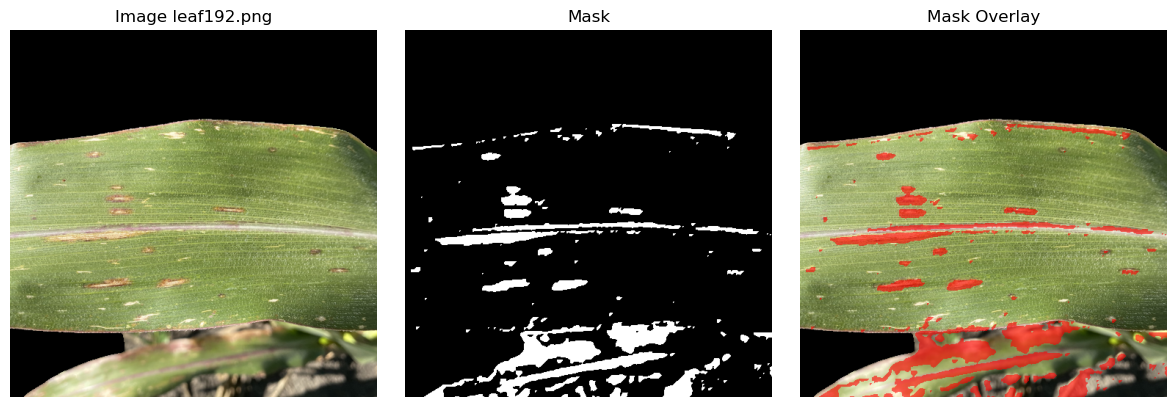

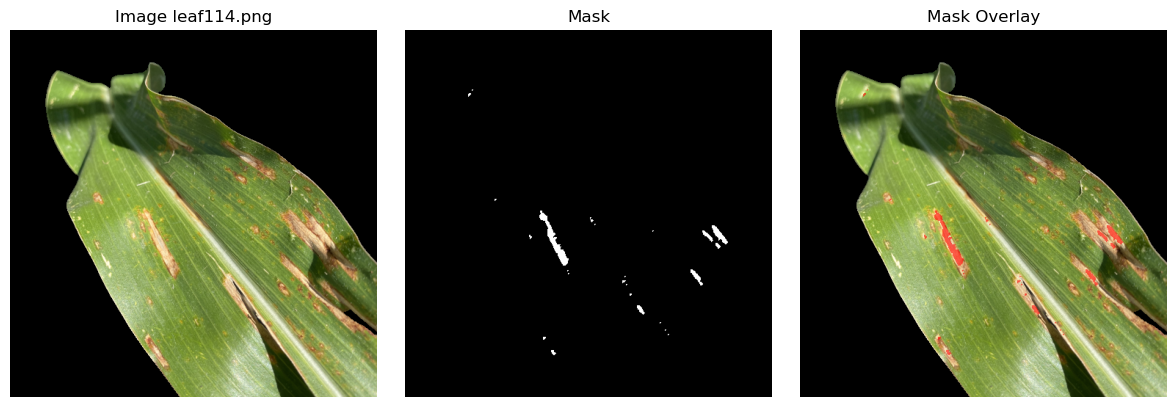

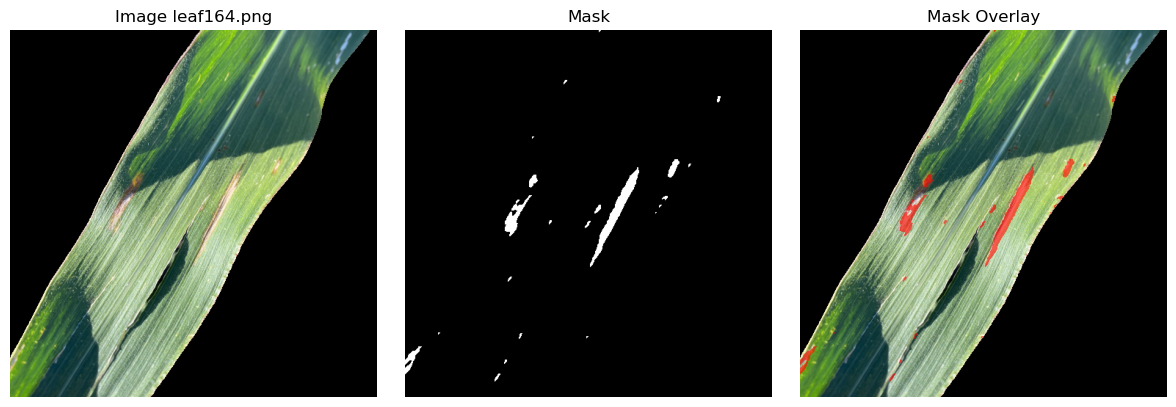

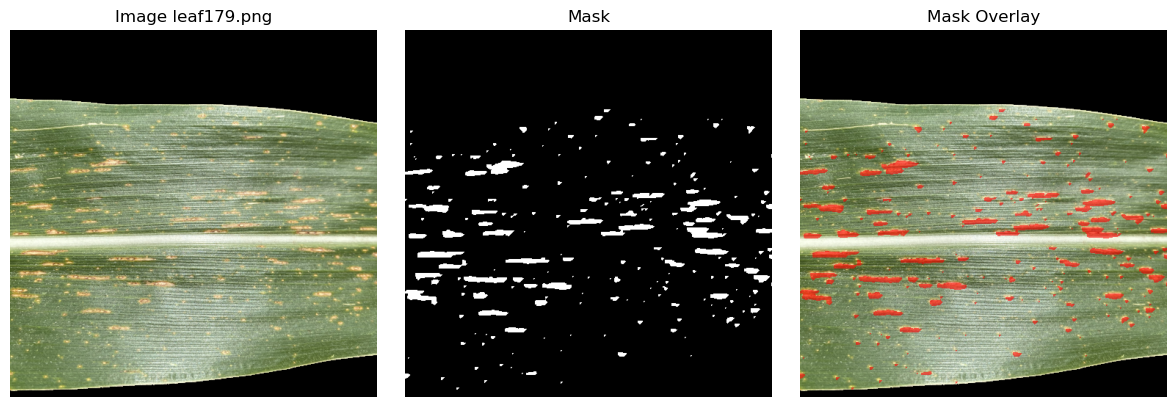

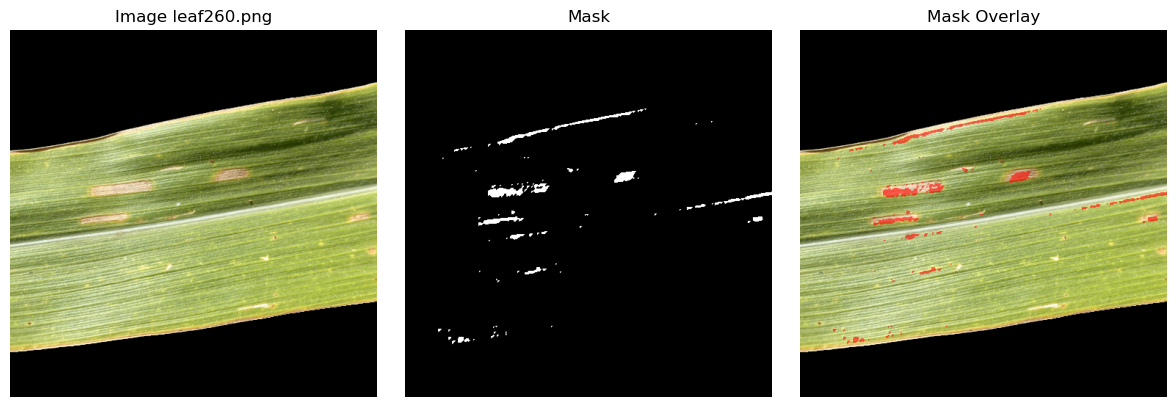

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import random
from PIL import Image

# Pick N random samples to visualize
N = 5
samples = random.sample(image_files, min(N, len(image_files)))

for fname in samples:
    img_path = os.path.join(image_folder, fname)
    img = cv2.imread(img_path)
    masks = generate_masks(img, image_name=fname)
    mask = masks['binary_mask']

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Image ' + img_path.split('/')[-1])
    axes[0].axis('off')

    axes[1].imshow(mask, cmap='gray')
    axes[1].set_title('Mask')
    axes[1].axis('off')

    overlay = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(float) / 255.0
    mask_array = mask / 255.0
    red_overlay = np.zeros((*mask_array.shape, 4))
    red_overlay[..., 0] = 1.0
    red_overlay[..., 3] = mask_array * 0.6

    axes[2].imshow(overlay)
    axes[2].imshow(red_overlay)
    axes[2].set_title('Mask Overlay')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

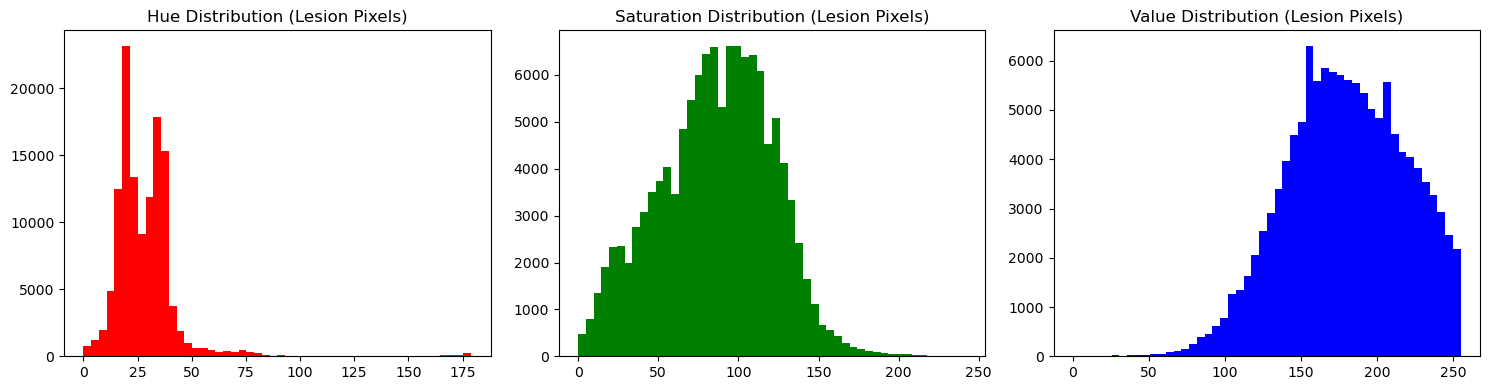

In [35]:
# --- Analyze Lesion Color Distribution in HSV ---
import matplotlib.pyplot as plt
import cv2
import numpy as np
import os

# Pick N random images to analyze
N = 10
sample_files = np.random.choice(image_files, min(N, len(image_files)), replace=False)

hsv_values = []
for fname in sample_files:
    img_path = os.path.join(image_folder, fname)
    img = cv2.imread(img_path)
    masks = generate_masks(img, image_name=fname)
    lesion_mask = masks['binary_mask'] > 0
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    # Get HSV values of lesion pixels only
    hsv_lesion = hsv_img[lesion_mask]
    hsv_values.append(hsv_lesion)

# Concatenate all lesion HSV values
hsv_values = np.concatenate(hsv_values, axis=0)

# Plot HSV distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(hsv_values[:,0], bins=50, color='r')
axes[0].set_title('Hue Distribution (Lesion Pixels)')
axes[1].hist(hsv_values[:,1], bins=50, color='g')
axes[1].set_title('Saturation Distribution (Lesion Pixels)')
axes[2].hist(hsv_values[:,2], bins=50, color='b')
axes[2].set_title('Value Distribution (Lesion Pixels)')
plt.tight_layout()
plt.show()

In [30]:
# --- Interactive Manual Annotation for All Images (Save HSV to Text, Auto-Advance, Overwrite) ---
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import os
from IPython.display import display

# Folder for saving HSV values text file
hsv_save_path = r'C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/manual/hsv_thresholds.txt'

# List of images
image_files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))]
image_files = sorted(image_files)

# Image index slider
img_idx = widgets.IntSlider(value=0, min=0, max=len(image_files)-1, step=1, description='Image Index')

# HSV sliders
hue_min = widgets.IntSlider(value=10, min=0, max=179, description='Hue Min')
hue_max = widgets.IntSlider(value=40, min=0, max=179, description='Hue Max')
sat_min = widgets.IntSlider(value=40, min=0, max=255, description='Sat Min')
sat_max = widgets.IntSlider(value=140, min=0, max=255, description='Sat Max')
val_min = widgets.IntSlider(value=100, min=0, max=255, description='Val Min')
val_max = widgets.IntSlider(value=255, min=0, max=255, description='Val Max')

# Navigation buttons
prev_button = widgets.Button(description='Previous', button_style='info')
next_button = widgets.Button(description='Next', button_style='info')
save_button = widgets.Button(description='Save HSV', button_style='success')

def update_index(change):
    if change['owner'] == prev_button and img_idx.value > 0:
        img_idx.value -= 1
    elif change['owner'] == next_button and img_idx.value < len(image_files)-1:
        img_idx.value += 1

prev_button.on_click(lambda b: update_index({'owner': prev_button}))
next_button.on_click(lambda b: update_index({'owner': next_button}))

def show_annotated_mask(img_idx, hue_min, hue_max, sat_min, sat_max, val_min, val_max):
    img_path = os.path.join(image_folder, image_files[img_idx])
    img = cv2.imread(img_path)
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lower = np.array([hue_min, sat_min, val_min])
    upper = np.array([hue_max, sat_max, val_max])
    mask = cv2.inRange(hsv_img, lower, upper)
    overlay = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(float) / 255.0
    mask_array = mask / 255.0
    red_overlay = np.zeros((*mask_array.shape, 4))
    red_overlay[..., 0] = 1.0
    red_overlay[..., 3] = mask_array * 0.6

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'Original: {image_files[img_idx]}')
    axes[0].axis('off')
    axes[1].imshow(mask, cmap='gray')
    axes[1].set_title('Thresholded Mask')
    axes[1].axis('off')
    axes[2].imshow(overlay)
    axes[2].imshow(red_overlay)
    axes[2].set_title('Mask Overlay')
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()

def on_save_clicked(b):
    img_name = image_files[img_idx.value]
    low = [hue_min.value, sat_min.value, val_min.value]
    up = [hue_max.value, sat_max.value, val_max.value]
    line = f'{img_name},{low[0]},{low[1]},{low[2]},{up[0]},{up[1]},{up[2]}\n'
    # Read all lines except the one for current image
    if os.path.exists(hsv_save_path):
        with open(hsv_save_path, 'r') as f:
            lines = f.readlines()
        lines = [l for l in lines if not l.startswith(f'{img_name},')]
    else:
        lines = []
    # Add/replace current line
    lines.append(line)
    with open(hsv_save_path, 'w') as f:
        f.writelines(lines)
    print(f'Saved HSV for {img_name}: low={low}, up={up}')
    # Auto-advance to next image if not last
    if img_idx.value < len(image_files) - 1:
        img_idx.value += 1

save_button.on_click(on_save_clicked)

controls = {'img_idx': img_idx, 'hue_min': hue_min, 'hue_max': hue_max, 'sat_min': sat_min, 'sat_max': sat_max, 'val_min': val_min, 'val_max': val_max}
out = widgets.interactive_output(show_annotated_mask, controls)

ui = widgets.HBox([prev_button, next_button, img_idx])
sliders = widgets.VBox([hue_min, hue_max, sat_min, sat_max, val_min, val_max, save_button])
display(ui, sliders, out)

Output()

In [ ]:
# --- Batch Manual Annotation for Multiple Images ---
import cv2
import numpy as np
import os
from PIL import Image
from tqdm.notebook import tqdm

# Output folder for batch manual masks
batch_annot_mask_folder = r'C:/Users/henry/Desktop/isef2026/data/masks/lesion_real/gls/manual_batch/'
os.makedirs(batch_annot_mask_folder, exist_ok=True)

# Set HSV threshold values (adjust as needed)
hue_min, hue_max = 10, 40
sat_min, sat_max = 40, 140
val_min, val_max = 100, 255

lower = np.array([hue_min, sat_min, val_min])
upper = np.array([hue_max, sat_max, val_max])

for fname in tqdm(image_files, desc='Batch Manual Annotation'):
    img_path = os.path.join(image_folder, fname)
    img = cv2.imread(img_path)
    if img is None:
        print(f'Warning: Image not found or could not be read at {img_path}')
        continue
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv_img, lower, upper)
    mask_filename = f'manual_mask_{os.path.splitext(fname)[0]}.png'
    mask_path = os.path.join(batch_annot_mask_folder, mask_filename)
    Image.fromarray(mask).save(mask_path)
    # Optionally print progress
    # print(f'Saved mask: {mask_path}')
print('Batch manual annotation complete. Masks saved.')

Batch Manual Annotation:   0%|          | 0/263 [00:00<?, ?it/s]

Batch manual annotation complete. Masks saved.


: 